# Which cell types are in my region?

The MERFISH dataset gives the spatial position and transcriptomic cell type of roughly
**8.9 million** individual cells, registered into the Allen reference space. Unlike the gene
expression atlas it is not a voxel grid — it is a table of cells with coordinates, so you can
plot individual cells and group them however the taxonomy allows.

For how this dataset relates to the others IBL repackages, see
[External data in the common space](../explanation/external-data-in-the-common-space.qmd).


How to cite this: see [Citations](../citations.qmd).

## Loading the tables

`merfish.load()` returns **seven** dataframes: the cells themselves, plus the four levels of
the cell-type taxonomy and two lookup tables.

| Dataframe | Shape | What it holds |
|---|---|---|
| `df_cells` | (8 879 868, 11) | One row per cell: position, Allen id, type labels |
| `df_classes` | (35, 3) | Coarsest taxonomy level |
| `df_subclasses` | (339, 4) | |
| `df_supertypes` | (1202, 4) | |
| `df_clusters` | (5323, 5) | Finest taxonomy level |
| `df_genes` | (1672, 4) | The gene panel |
| `df_neurotransmitters` | (9, 2) | Neurotransmitter lookup |

The taxonomy nests `cluster` → `supertype` → `subclass` → `class`, so you can colour or
aggregate at whichever level suits the question.

The first call downloads the data from the `ibl-brain-wide-map-public` S3 bucket and caches
it. It is a large download. `dask` is used to read the cell table if you have it installed,
and pandas otherwise — neither is required.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

from iblutil.numerical import ismember
from iblatlas.atlas import AllenAtlas
from iblatlas.genomics import merfish

df_cells, df_classes, df_subclasses, df_supertypes, df_clusters, df_genes, df_neurotransmitters = merfish.load()

## Plotting a section

Cell coordinates are in the `x`, `y`, `z` columns, bregma-relative and in the usual
(ML, AP, DV) order. `ismember` matches each cell's `Allen_id` against the atlas region table,
which is what lets the same cells be coloured either by anatomy or by transcriptomic class.

`merfish.int2rgb` unpacks the packed RGBA integers the type tables store into colours
matplotlib can use.

Below, one coronal section is drawn twice: coloured by Allen region on the left, and by
transcriptomic class on the right. Where the two agree, anatomy and transcriptomics are
telling the same story; where they differ is usually the interesting part.


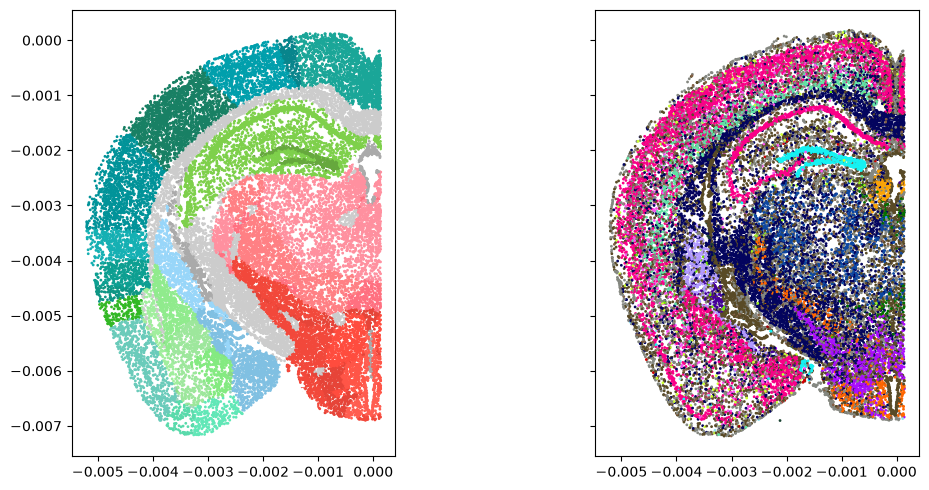

In [2]:
ba = AllenAtlas()
_, rids = ismember(df_cells['Allen_id'], ba.regions.id)
xyz = df_cells.loc[:, ['x', 'y', 'z']].values

def plot_section(section, ix, iy):
    i = df_cells['brain_section_label'] == section  # 085
    rgb_classes = merfish.int2rgb(df_classes.loc[df_cells.loc[i, 'class'], 'class_rgba'])
    fig, axs = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12, 5))
    axs[0].scatter(xyz[i, ix], xyz[i, iy], c=ba.regions.rgba[rids[i], :].astype(np.double) / 255, s=1)
    axs[1].scatter(xyz[i, ix], xyz[i, iy], c=rgb_classes, s=1)
    axs[0].set_aspect('equal', 'box')
    axs[1].set_aspect('equal', 'box')
    fig.tight_layout()
    return fig, axs

fig, axs = plot_section(section="Zhuang-ABCA-1.085", ix=0, iy=2)

## Cells or volumes?

This page loads **cells**. There is also a volume form of the same data —
`merfish.load_volume()` — which gives cell-type densities on the 200 µm grid shared with the
gene expression atlas.

Two defaults are worth knowing before you compare them:

- `load_volume` returns the **denoised** volume by default (`label='processed'`: NaNs filled,
  Gaussian-smoothed, renormalised). Pass `label=''` for the raw one. The gene expression
  loader, `agea.load`, returns the **raw** volume by default — so the two differ, and
  comparing them naively compares a smoothed volume against an unsmoothed one.
- `load_volume` **drops non-neuronal cell types** unless you pass
  `include_non_neuronal=True`.


## Citing this data

See [Citations](../citations.qmd) for what to cite for each dataset.


## In my region

The example region is VISp, primary visual cortex; replace `'VISp'` with the Beryl acronym of your own region. Each cell's `Allen_id` is the region it sits in, so the cells of a region are the ones whose id maps to it at the Beryl level:

In [3]:
in_region = ba.regions.id2acronym(df_cells['Allen_id'].to_numpy(), mapping='Beryl') == 'VISp'
cells_in_region = df_cells[in_region]
print(f'{len(cells_in_region)} cells')

141873 cells


The share of each cell class among them, as a percentage of the cells in the region:

In [4]:
class_shares = cells_in_region['class'].value_counts(normalize=True).mul(100).round(1)
class_shares[class_shares > 0].rename(index=df_classes['class']).to_frame('% of cells')

,% of cells
class,
01 IT-ET Glut,49.6
02 NP-CT-L6b Glut,12.1
33 Vascular,11.9
30 Astro-Epen,9.9
31 OPC-Oligo,5.9
07 CTX-MGE GABA,4.8
34 Immune,3.4
06 CTX-CGE GABA,2.2


And the ten largest subclasses:

In [5]:
subclass_shares = cells_in_region['subclass'].value_counts(normalize=True).mul(100).round(1)
subclass_shares.rename(index=df_subclasses['subclass']).head(10).to_frame('% of cells')

,% of cells
subclass,
006 L4/5 IT CTX Glut,21.2
007 L2/3 IT CTX Glut,18.3
030 L6 CT CTX Glut,10.5
319 Astro-TE NN,9.9
333 Endo NN,8.9
004 L6 IT CTX Glut,3.8
327 Oligo NN,3.8
022 L5 ET CTX Glut,3.4
334 Microglia NN,3.3
